# Linear Time-Invariant (LTI) Systeme und Faltung

## LTI Systeme

Ein LTI-System ist ein lineares zeitinvariantes System – ein zentrales Konzept in der Signalverarbeitung, Systemtheorie und Regelungstechnik. Es beschreibt, wie ein System auf Eingangssignale reagiert, und hat zwei wichtige Eigenschaften, linearität (Skalierung und Addition der Eingänge führen zu entsprechender Skalierung und Addition der Ausgänge) und Zeitinvarianz (sein Verhalten im Zeitverlauf konstant bleibt – mit anderen Worten: Das System reagiert stets identisch, unabhängig vom Zeitpunkt des Eingangssignals.)

In der digitalen Signalverarbeitung ist es üblich, eine diskrete Funktion (also ein Signal x[n]) als eine Linearkombination von verschobenen Deltafunktionen zu schreiben:

$x[n] = \sum_{k=-\infty}^{\infty} x[k] \delta[n - k]$

Hierbei ist:

- \($\delta[n - k]$\): die verschobene diskrete Deltafunktion (auch **Einheitsimpuls** genannt),
- \(x[k]\): der **Skalierungsfaktor** (das Gewicht) für jede Deltafunktion.


LTI-Systeme sind wichtig weil sie mathematisch gut analysierbar sind. Die Systemantwort auf ein beliebiges Eingangssignal kann durch Faltung mit der Impulsantwort berechnet werden. Sie lassen sich mit Fourier- und Z-Transformationen analysieren.


**📝  Aufgabe 1: Eingangssignal**

Erstelle und zeichne ein Eingangssignal, das 5 diskrete Werte mit unterschiedlichen Amplituden enthält.

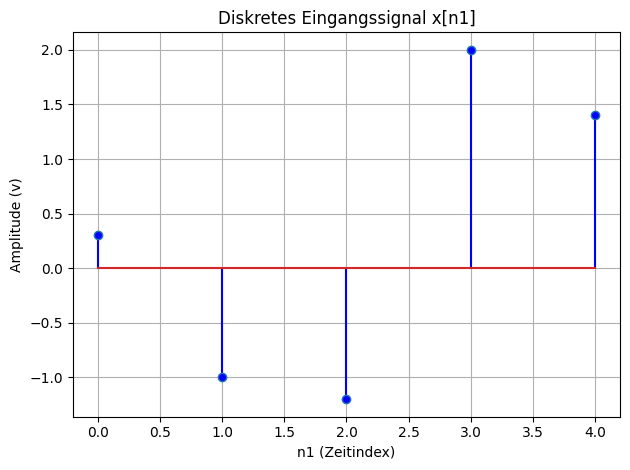

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Definiere das diskrete Signal mit 5 Werten unterschiedlicher Amplitude
n1 = list(range(5))  # Zeitindizes von 0 bis 4
x = [0.3, -1, -1.2, 2, 1.4 ]  # Amplituden

# Erstelle das Stem-Plot
markerline, stemlines, baseline = plt.stem(n1, x)
plt.setp(markerline, 'markerfacecolor', 'blue')
plt.setp(stemlines, 'color', 'blue')

# Diagrammbeschriftung auf Deutsch
plt.title("Diskretes Eingangssignal x[n1]")
plt.xlabel("n1 (Zeitindex)")
plt.ylabel("Amplitude (v)")
plt.grid(True)
plt.tight_layout()
plt.show()


**📝  Aufgabe 2: Impulsantwort**

Erstelle und zeichne eine Impulsantwort, die 4 diskrete Werte mit unterschiedlichen Amplituden enthält.

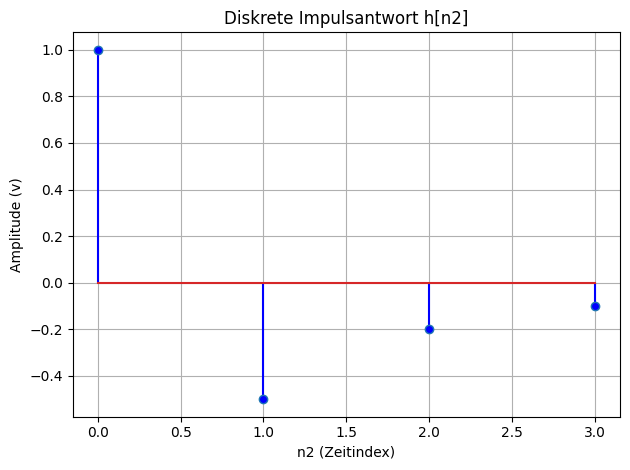

In [2]:
# Definiere das diskrete Signal mit Werten unterschiedlicher Amplitude
n2= list(range(4))  # Zeitindizes
h = [1, -0.5, -0.2, - 0.1]  # Amplituden

# Erstelle das Stem-Plot
markerline, stemlines, baseline = plt.stem(n2, h)
plt.setp(markerline, 'markerfacecolor', 'blue')
plt.setp(stemlines, 'color', 'blue')

# Diagrammbeschriftung auf Deutsch
plt.title("Diskrete Impulsantwort h[n2]")
plt.xlabel("n2 (Zeitindex)")
plt.ylabel("Amplitude (v)")
plt.grid(True)
plt.tight_layout()
plt.show()

## Faltung

Die Faltung ist eine mathematische Methode, um zwei Signale zu einem dritten Signal zu kombinieren. Sie ist die wichtigste Technik in der digitalen Signalverarbeitung. Mithilfe der Strategie der Impulszerlegung werden Systeme durch ein Signal beschrieben, das als Impulsantwort bezeichnet wird.([[1]](#1))

Angenommen, wir haben ein LTI-System mit einer Übertragungsfunktion \( $F[\cdot]$ \). Seine Impulsantwort ist \($ F[\delta[n]] $\) und wird dargestellt als:

$
h[n] = F[\delta[n]]
$

Wenn wir nun dieses LTI-System auf ein Eingangssignal \(x[n]\) anwenden möchten (**Aufmerken** \(x[k]\) ist der Skalierungsfaktor für jede Deltafunktion.):

$ y[n] = F[x[n]] = F[\sum_{k=-\infty}^{\infty} x[k] \cdot \delta[n - k]] $

$= \sum_{k=-\infty}^{\infty} F[x[k] \delta[n - k]]  $  (Homogenität)

$= \sum_{k=-\infty}^{\infty} x[k] F[\delta[n - k]]  $  (Verschiebungsinvarianz)

$= \sum_{k=-\infty}^{\infty} x[k] h[n - k]  $ 

Dies ist eine Faltung.

$y[n] = x[n] * h[n] = \sum_{k=-\infty}^{\infty} x[k] h[n - k]  $ 

## Eigenschaften der Faltung
1. Kommutativität:
$𝑎[𝑛]∗𝑏[𝑛]=𝑏[𝑛]∗𝑎[𝑛]$

2. Assoziativität:
$𝑎[𝑛]∗(𝑏[𝑛]∗𝑐[𝑛])=(𝑎[𝑛]∗𝑏[𝑛])∗𝑐[𝑛]$

3. Distributivität:
$𝑎[𝑛]∗(𝑏[𝑛]+𝑐[𝑛])=𝑎[𝑛]∗𝑏[𝑛]+𝑐[𝑛]∗𝑎[𝑛]$


## Der Faltungsoperation

Die ursprüngliche Faltungsformel für die beiden gegebenen Signale, kann wie folgt angegeben werden:

$y[n] = x[n] * h[n] = \sum_{k=-\infty}^{\infty} x[k] h[n - k] =  \sum_{k=0}^{M-1} x[k] h[n - k] $ 

Formel erlaubt individuelle Berechnung von jedem Punkt des Ausgangssignals

Index n: Welcher Punkt im Ausgangssignal

Index k: Iterator durch die Impulsantwort

M - 1: Die Länge des Ausgangssignals. Die Länge einer Faltung entspricht der Summe der Längen des Eingangssignals und der Impulsantwort minus eins.

Länge x[n] = 5

Länge h[n] = 4

$y[n] = x[n] * h[n] = \sum_{k=0}^{7} x[k] h[n - k] $ 

Die Faltung kann aus zwei Perspektiven analysiert werden: der Eingangssignal-Perspektive und der Ausgangssignal-Perspektive.

Aus Sicht des Eingangssignals: Zerlege das Eingangssignal, leite die einzelnen Komponenten durch das System und setze daraus das Ausgangssignal wieder zusammen.

Aus Sicht des Ausgangssignals: Jeder Punkt im Ausgangssignal wird von mehreren Punkten des Eingangssignals beeinflusst – gewichtet durch eine gespiegelte Impulsantwort.

**📝  Aufgabe 3: Faltung**

Berechne und zeichne die Faltung der zuvor definierten Signale aus sicht des Eingangssignals. Stelle das Ergebnis jedes Berechnungsschritts grafisch in einem einzelnen Diagramm dar. Vergleiche das Ergebnis mit dem Ergebnis der Funktion ```convolve()```.

Eingangssignal-Perspektive:

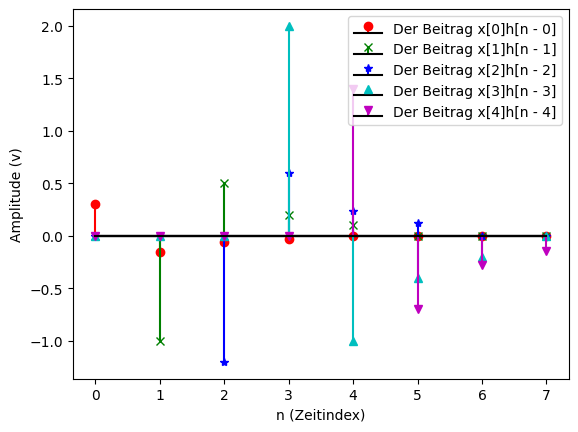

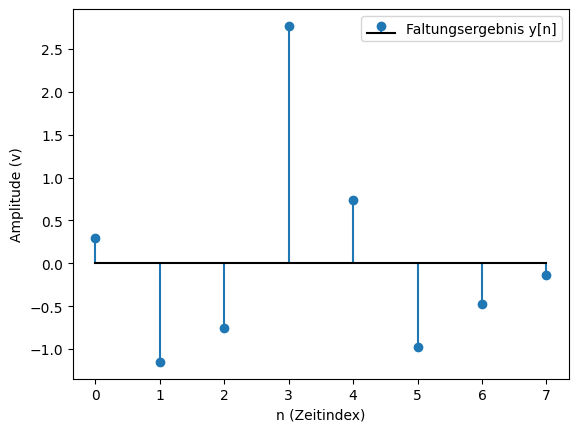

Faltungsergebnis y[n]: [ 0.3  -1.15 -0.76  2.77  0.74 -0.98 -0.48 -0.14]
Faltungsergebnis mit convolve( ) y[n]: [ 0.3  -1.15 -0.76  2.77  0.74 -0.98 -0.48 -0.14]


In [ ]:
#x = [0.3, -1, -1.2, 2, 1.4 ]
#h = [1, -0.5, -0.2, -0.1]
# Faltung der Signale
n = len(x) + len(h) - 1  # Länge des Ergebnisses
#initialize array for convolution result
decomp = np.zeros((len(x), n))


# x[0] = 0.3
#h[n-0] = h[n] = 1 δ[n-0] - 0.5 δ[n-1] - 0.2 δ[n-2] - 0.1 δ[n-3]
decomp[0] = [0.3 * 1, 0.3 * -0.5, 0.3 * -0.2 , 0.3 * -0.1, 0, 0, 0, 0]

#x[1] = -1
#h[n-1] = h[n-1] = 1 δ[n-1] - 0.5 δ[n-2] - 0.2 δ[n-3] - 0.1 δ[n-4]
decomp[1] = [0, -1 * 1 , -1 * -0.5 , -1 * -0.2 , -1 * -0.1, 0, 0, 0]

#x[2] = -1.2
#h[n-2] = h[n-2] = 1 δ[n-2] - 0.5 δ[n-3] - 0.2 δ[n-4] - 0.1 δ[n-5]
decomp[2] = [0, 0, -1.2 * 1 , -1.2 * -0.5 , -1.2 * -0.2 , -1.2 * -0.1, 0, 0]

#x[3] = 2
#h[n-3] = h[n-3] = 1 δ[n-3] - 0.5 δ[n-4] - 0.2 δ[n-5] - 0.1 δ[n-6]
decomp[3] = [0, 0, 0, 2 * 1 , 2 * -0.5 , 2 * -0.2 , 2 * -0.1, 0]

#x[4] = 1.4
#h[n-4] = h[n-4] = 1 δ[n-4] - 0.5 δ[n-5] - 0.2 δ[n-6] - 0.1 δ[n-7]
decomp[4] = [0, 0, 0, 0, 1.4 * 1 , 1.4 * -0.5 , 1.4 * -0.2 , 1.4 * -0.1]

# Faltungsergebnis
y_result = np.sum(decomp, axis=0)
y_result1= np.convolve(x, h, mode= 'full')

colors = ['r', 'g', 'b', 'c', 'm'] 
shapes = ['o', 'x', '*', '^', 'v']
# Plotten der Faltungsergebnisse
for i in range(len(x)):
    plt.stem(range(n), decomp[i], label=f'Der Beitrag x[{i}]h[n - {i}]', linefmt=colors[i], markerfmt=colors[i] + shapes[i], basefmt='black')
    plt.xlabel("n (Zeitindex)")
    plt.ylabel("Amplitude (v)")
    plt.legend()
plt.show()    

plt.stem(range(n), y_result, label='Faltungsergebnis y[n]', basefmt='black')
plt.xlabel("n (Zeitindex)")
plt.ylabel("Amplitude (v)")
plt.legend()
plt.show()
print("Faltungsergebnis y[n]:", y_result)
print("Faltungsergebnis mit convolve( ) y[n]:", y_result1)

**📝  Aufgabe 4: Faltung**

Berechne und zeichne die Faltung der zuvor definierten Signale aus Sicht des Ausgangssignals.
Ausgangssignal-Perspektive:

Faltungsmachine: Wir müssen die Impulsantwort spiegeln und sie von links nach rechts über das gesamte Eingangssignal anwenden. 

![alt text](attachments/faltungsmachine.png) © genommen von [[1]](#1)

Was passiert mit y[0], y[1], y[2], y[5], y[6] und y[7]? Welche Folgen könnte das haben?

In [4]:
#x = [0.3, -1, -1.2, 2, 1.4 ]
#h = [1, -0.5, -0.2, - 0.1]
#Ausgangssignal
y = np.zeros(n)

#y[0] = x[0]h[0]
y[0] =  0.3 * 1

#y[1] = x[0]h[1] + x[1]h[0]
y[1] = 0.3 * - 0.5 + -1 * 1

#y[2] = x[0]h[2] + x[1]h[1] + x[2]h[0]
y[2] = 0.3 * -0.2 + -1 * -0.5 + -1.2 * 1

#y[3] = x[0]h[3] + x[1]h[2] + x[2]h[1] + x[3]h[0]
y[3] = 0.3 * -0.1 + -1 * -0.2 + -1.2 * -0.5 + 2 * 1

#y[4] = x[1]h[3] + x[2]h[2] + x[3]h[1] + x[4]h[0]
y[4] = -1 * -0.1 + -1.2 * -0.2 + 2 * -0.5 + 1.4 * 1

#y[5] = x[2]h[3] + x[3]h[2] + x[4]h[1]
y[5] = -1.2 * -0.1 + 2 * -0.2 + 1.4 * -0.5

#y[6] = x[3]h[3] + x[4]h[2]
y[6] = -1.2 * 0 + 2 * -0.1 + 1.4 * -0.2

#y[7] = x[4]h[3]
y[7] = 1.4 * -0.1

print("Faltungsergebnis y[n]:", y)


Faltungsergebnis y[n]: [ 0.3  -1.15 -0.76  2.77  0.74 -0.98 -0.48 -0.14]


**Quellen und Weiterführende Literatur:**

<a id="1">[1]</a> 
Smith, Steven W. (1997), The scientist and engineer's guide to digital signal processing. 1. ed. San Diego, Calif.: California Technical Publ. Online verfügbar unter https://www.dspguide.com/.